In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Input, Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

In [4]:
# 1. Generate training samples from -20 to +20
np.random.seed(42)
x = np.linspace(-20, 20, 1000).reshape(-1, 1)
y = 5 * x**10 + x**3 - x + 5
print(x, y)

[[-20.        ]
 [-19.95995996]
 [-19.91991992]
 [-19.87987988]
 [-19.83983984]
 [-19.7997998 ]
 [-19.75975976]
 [-19.71971972]
 [-19.67967968]
 [-19.63963964]
 [-19.5995996 ]
 [-19.55955956]
 [-19.51951952]
 [-19.47947948]
 [-19.43943944]
 [-19.3993994 ]
 [-19.35935936]
 [-19.31931932]
 [-19.27927928]
 [-19.23923924]
 [-19.1991992 ]
 [-19.15915916]
 [-19.11911912]
 [-19.07907908]
 [-19.03903904]
 [-18.998999  ]
 [-18.95895896]
 [-18.91891892]
 [-18.87887888]
 [-18.83883884]
 [-18.7987988 ]
 [-18.75875876]
 [-18.71871872]
 [-18.67867868]
 [-18.63863864]
 [-18.5985986 ]
 [-18.55855856]
 [-18.51851852]
 [-18.47847848]
 [-18.43843844]
 [-18.3983984 ]
 [-18.35835836]
 [-18.31831832]
 [-18.27827828]
 [-18.23823824]
 [-18.1981982 ]
 [-18.15815816]
 [-18.11811812]
 [-18.07807808]
 [-18.03803804]
 [-17.997998  ]
 [-17.95795796]
 [-17.91791792]
 [-17.87787788]
 [-17.83783784]
 [-17.7977978 ]
 [-17.75775776]
 [-17.71771772]
 [-17.67767768]
 [-17.63763764]
 [-17.5975976 ]
 [-17.55755756]
 [-17.51

In [5]:
# 2. Normalize input and output to the range [-1, 1]
x_scaler = MinMaxScaler(feature_range=(-1, 1))
y_scaler = MinMaxScaler(feature_range=(-1, 1))

x = x_scaler.fit_transform(x)
y = y_scaler.fit_transform(y)
print(x, y)

[[-1.        ]
 [-0.997998  ]
 [-0.995996  ]
 [-0.99399399]
 [-0.99199199]
 [-0.98998999]
 [-0.98798799]
 [-0.98598599]
 [-0.98398398]
 [-0.98198198]
 [-0.97997998]
 [-0.97797798]
 [-0.97597598]
 [-0.97397397]
 [-0.97197197]
 [-0.96996997]
 [-0.96796797]
 [-0.96596597]
 [-0.96396396]
 [-0.96196196]
 [-0.95995996]
 [-0.95795796]
 [-0.95595596]
 [-0.95395395]
 [-0.95195195]
 [-0.94994995]
 [-0.94794795]
 [-0.94594595]
 [-0.94394394]
 [-0.94194194]
 [-0.93993994]
 [-0.93793794]
 [-0.93593594]
 [-0.93393393]
 [-0.93193193]
 [-0.92992993]
 [-0.92792793]
 [-0.92592593]
 [-0.92392392]
 [-0.92192192]
 [-0.91991992]
 [-0.91791792]
 [-0.91591592]
 [-0.91391391]
 [-0.91191191]
 [-0.90990991]
 [-0.90790791]
 [-0.90590591]
 [-0.9039039 ]
 [-0.9019019 ]
 [-0.8998999 ]
 [-0.8978979 ]
 [-0.8958959 ]
 [-0.89389389]
 [-0.89189189]
 [-0.88988989]
 [-0.88788789]
 [-0.88588589]
 [-0.88388388]
 [-0.88188188]
 [-0.87987988]
 [-0.87787788]
 [-0.87587588]
 [-0.87387387]
 [-0.87187187]
 [-0.86986987]
 [-0.86786

In [6]:
# 3. Split data: 10% test, 10% validation, 80% training
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.10, random_state=42
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=1/9, random_state=42
)

In [8]:
# 4. Build DNN with 3 hidden layers: 32, 64, 128 neurons
model = Sequential([
    Input(shape=(1,)),
    Dense(32, activation='relu'),
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),
    Dense(1)
])

In [9]:
# 5. Display model architecture and parameters
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,625 (41.50 KB)

 Trainable params: 10,625 (41.50 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# 6. Compile model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae'],
    jit_compile=False
)

In [15]:
# 7. Train the DNN
history = model.fit(
    x_train, y_train,
    epochs=200,
    batch_size=32,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/200


W0000 00:00:1792951564.632881  434675 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792951564.713617  435303 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792951564.714193  435308 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792951564.715309  435309 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792951564.716286  435304 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792951564.717357  435299 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792951564.718660  435305 gpu_kernel_to_blob_pass.cc:190] Failed to co

 1/25 ━━━━━━━━━━━━━━━━━━━━ 1:40 4s/step - loss: 0.7410 - mae: 0.8346

W0000 00:00:1792951566.683299  434675 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1792951566.725082  434675 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.


25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.4746 - mae: 0.6021 - val_loss: 0.3446 - val_mae: 0.4291
Epoch 2/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2630 - mae: 0.3937 - val_loss: 0.2070 - val_mae: 0.2940
Epoch 3/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1492 - mae: 0.2541 - val_loss: 0.1245 - val_mae: 0.2013
Epoch 4/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0962 - mae: 0.1948 - val_loss: 0.0970 - val_mae: 0.2006
Epoch 5/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0828 - mae: 0.1932 - val_loss: 0.0851 - val_mae: 0.1919
Epoch 6/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0705 - mae: 0.1682 - val_loss: 0.0661 - val_mae: 0.1546
Epoch 7/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0586 - mae: 0.1403 - val_loss: 0.0542 - val_mae: 0.1312
Epoch 8/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0455 - mae: 0.1174 - val_loss: 0.0434 - val_mae: 0.1052
Epoch 9/200
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0374 - mae: 0.0

In [16]:
# 8. Predict using test data
y_pred = model.predict(x_test)

# Convert normalized predictions and true values back to original scale
y_test_original = y_scaler.inverse_transform(y_test)
y_pred_original = y_scaler.inverse_transform(y_pred)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


In [17]:
# 9. Evaluate test performance
test_loss, test_mae = model.evaluate(x_test, y_test, verbose=0)

print("Test MSE (normalized):", test_loss)
print("Test MAE (normalized):", test_mae)

Test MSE (normalized): 0.0003555233415681869
Test MAE (normalized): 0.01275005005300045


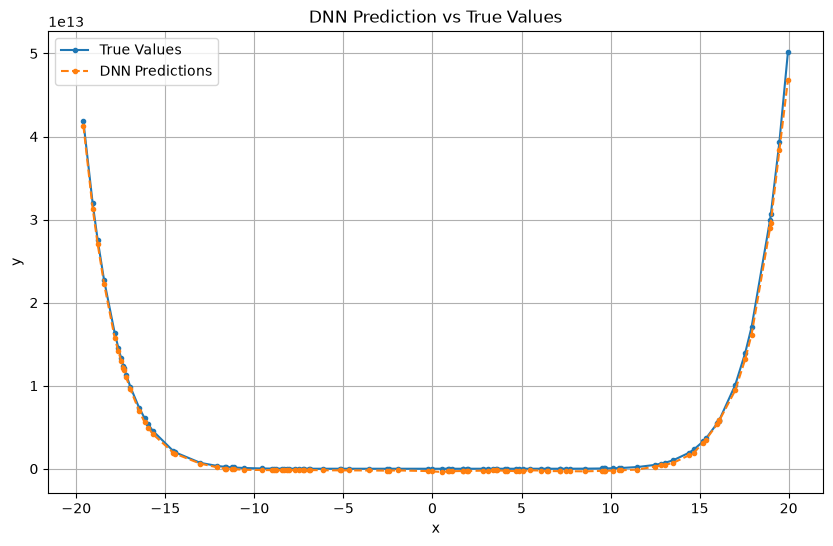

In [18]:
# 10. Plot true values vs predicted values
x_test_original = x_scaler.inverse_transform(x_test)

# Sort points for a clear graph
indices = np.argsort(x_test_original[:, 0])

plt.figure(figsize=(10, 6))
plt.plot(
    x_test_original[indices, 0],
    y_test_original[indices, 0],
    label='True Values',
    marker='.',
    linestyle='-'
)
plt.plot(
    x_test_original[indices, 0],
    y_pred_original[indices, 0],
    label='DNN Predictions',
    marker='.',
    linestyle='--'
)

plt.xlabel('x')
plt.ylabel('y')
plt.title('DNN Prediction vs True Values')
plt.legend()
plt.grid(True)
plt.show()

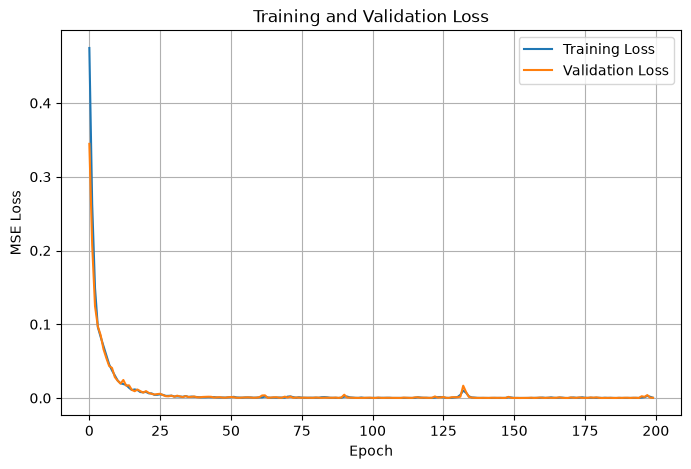

In [19]:
# 11. Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()